# 02 · The data and what the model sees

## What this notebook shows

This notebook explains the **input** side of the forecast, in four steps:

1. **The data**: how many SIM (Montréal fire service) interventions happen each day, in
   each of the six operational divisions, from 2020 to September 2026.
2. **The rule of the game**: when a forecast is made, and which days it is allowed to see.
3. **The features**: the 25 numbers that describe one division on one day and that the
   models read to make a forecast.
4. **The baselines**: two very simple forecasting rules that any real model has to beat.

Nothing here trains a model; the next notebook (`03_models_and_ensemble`) does that.

## Glossary

- **Division**: one of the six areas of Montréal that the fire service is split into
  (numbered 1 to 6). We forecast each one separately.
- **Forecast**: our best guess, made in advance, of how many interventions a division will
  have on a given day.
- **Cutoff**: the last day whose counts are known when the forecast is made. The city
  publishes the data about 2 days late, so the cutoff is always behind "today".
- **Feature**: one number the model looks at, such as "the average count over the last
  7 days" or "the target day is a Saturday".
- **Baseline**: a simple rule of thumb (for example, "same as the average of the last 13
  Saturdays"). A model is only useful if it does better than the baseline.

## Setup

Load the libraries and the project's own package (`ycit440_sim_forecast`). The `chdir`
line makes the notebook work whether it is started from the repo root or from
`notebooks/`. Charts are drawn at a modest resolution to keep the file small.

In [ ]:
import datetime as dt
import os
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns
from matplotlib.patches import Rectangle

from ycit440_sim_forecast import baseline, features, spec

# VS Code starts notebooks in notebooks/; every path below is relative to the repo root.
if not Path("pyproject.toml").exists():
    os.chdir(Path.cwd().parent)

A few display settings: a clean chart style, one fixed colour per division, and wider
tables. `check` stops the notebook with an error if a number doesn't match what we
expect, so a wrong result can't slip through silently.

In [ ]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (10, 4)})
pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(80)
DIVISIONS = [1, 2, 3, 4, 5, 6]
DIV_COLOR = dict(zip(DIVISIONS, sns.color_palette("tab10", 6), strict=True))
V2 = spec.V2_DAILY  # the forecasting rule used throughout the project


def check(cond: bool, msg: str) -> None:
    """Stop the notebook when something doesn't match."""
    if not cond:
        raise AssertionError(msg)

## 1. The data

The cleaned data has one row per **day and division**: the date, the division number,
`n` (the number of interventions that day) and `n_fr` (how many of them were
first-responder medical calls). One day, 2024-12-31, is missing from the city's files, so
its count is empty.

In [ ]:
history = pl.read_parquet("data/processed/division_day.parquet")
print(f"{history.height:,} rows, {history['date'].min()} to {history['date'].max()}")
missing = history.filter(pl.col("n").is_null())["date"].unique().to_list()
print(f"days with a missing count: {missing}")
history.head(6)

14,754 rows, 2020-01-01 to 2026-09-24
days with a missing count: [datetime.date(2024, 12, 31)]


date,DIVISION,n,n_fr
date,i64,u32,u32
2020-01-01,1,35,31
2020-01-01,2,67,53
2020-01-01,3,55,39
2020-01-01,4,70,56
2020-01-01,5,64,49
2020-01-01,6,69,57


### The whole city, day by day

Adding the six divisions gives the city total. The thin grey line is the count for each
day; the black line is the **28-day rolling mean** (the average of the last 28 days,
recomputed every day), which smooths out the day-to-day noise so the trend is visible.
Note the dip in spring 2020 (COVID lockdown) and the slower period around the turn of
2025–2026. A handful of exceptional days (the April 2023 ice storm reached 1,712
interventions on 6 April) go off the top of the chart, which is cut at 600 so the normal
days stay readable.

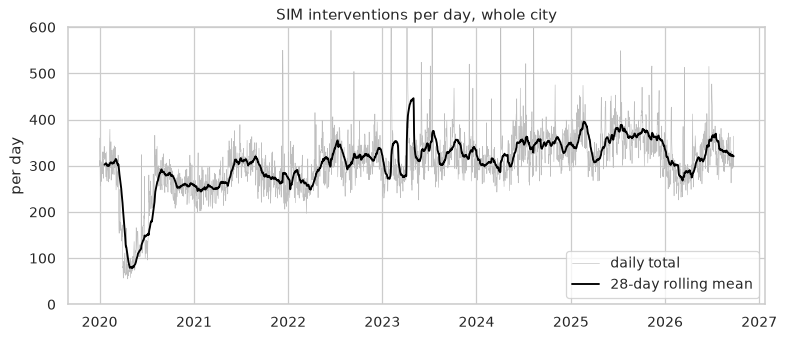

In [ ]:
city = (
    history.group_by("date")
    .agg(pl.col("n").sum().alias("n"), pl.col("n").null_count().alias("missing"))
    .with_columns(pl.when(pl.col("missing") == 0).then(pl.col("n")))
    .sort("date")
    .with_columns(mean_28d=pl.col("n").rolling_mean(28, min_samples=20))
)
fig, ax = plt.subplots()
ax.plot(city["date"], city["n"], color="0.75", lw=0.5, label="daily total")
ax.plot(
    city["date"], city["mean_28d"], color="black", lw=1.5, label="28-day rolling mean"
)
ax.set(title="SIM interventions per day, whole city", ylabel="per day", ylim=(0, 600))
ax.legend(loc="lower right");

### Each division

The same picture per division, using the 28-day rolling mean only (the raw daily lines
would overlap into a blur). Divisions differ in size, but they rise and fall together,
which is why one approach can forecast all six.

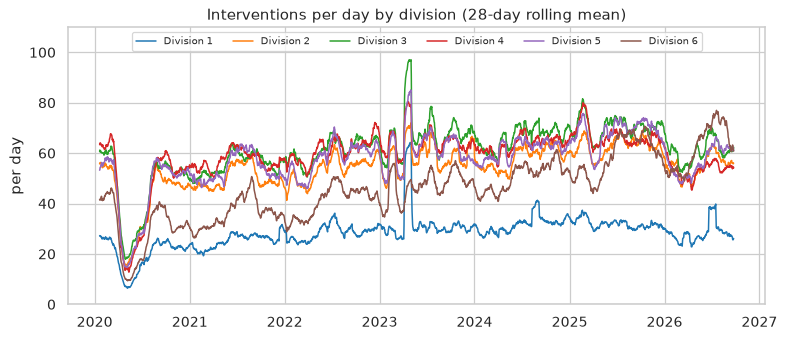

In [ ]:
fig, ax = plt.subplots()
for div in DIVISIONS:
    one = history.filter(pl.col("DIVISION") == div).sort("date")
    smooth = one["n"].rolling_mean(28, min_samples=20)
    ax.plot(one["date"], smooth, color=DIV_COLOR[div], lw=1.2, label=f"Division {div}")
ax.set(
    title="Interventions per day by division (28-day rolling mean)", ylabel="per day"
)
ax.set_ylim(0, 110)
ax.legend(ncols=6, loc="upper center", fontsize=8);

## 2. The rule of the game: when is a forecast made?

The city publishes its intervention data about **2 days late**. So a forecast for day
**D** is made on the evening of **D−1** (the day before), but the newest complete count
available at that time is for **D−3**. Days D−2 and D−1 are not known yet.

The project's settings say exactly this: a publication lag of 2 days, a lead of 1 day
(forecast one day ahead), and a window of 1 day (we forecast a single day).

In [ ]:
issue = dt.date(2020, 12, 31)
print(V2)
print(f"forecast issued on {issue}")
print(f"  last known counts (cutoff): {V2.cutoff(issue)}")
print(f"  day being forecast (target): {V2.target_start(issue)}")

ForecastSpec(publication_lag_days=2, lead_days=1, window_days=1)
forecast issued on 2020-12-31
  last known counts (cutoff): 2020-12-29
  day being forecast (target): 2021-01-01


The same rule as a picture, using the example above. Green is what the forecaster can
use, grey is what exists but hasn't been published yet, and orange is the day being
forecast.

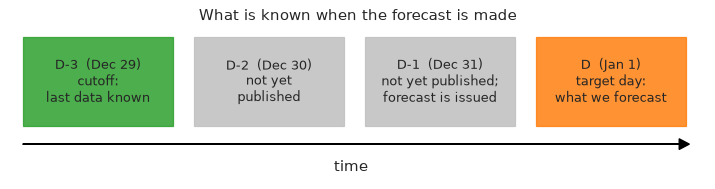

In [ ]:
steps = [
    ("D-3  (Dec 29)\ncutoff:\nlast data known", "#2ca02c"),
    ("D-2  (Dec 30)\nnot yet\npublished", "0.75"),
    ("D-1  (Dec 31)\nnot yet published;\nforecast is issued", "0.75"),
    ("D  (Jan 1)\ntarget day:\nwhat we forecast", "#ff7f0e"),
]
fig, ax = plt.subplots(figsize=(10, 2.2))
for x, (text, color) in enumerate(steps):
    ax.add_patch(Rectangle((x * 2.5, 0), 2.2, 1, color=color, alpha=0.85))
    ax.text(x * 2.5 + 1.1, 0.5, text, ha="center", va="center", fontsize=10)
ax.arrow(0, -0.2, 9.6, 0, head_width=0.12, head_length=0.15, color="black")
ax.text(4.8, -0.5, "time", ha="center")
ax.set(
    xlim=(-0.2, 10), ylim=(-0.6, 1.1), title="What is known when the forecast is made"
)
ax.axis("off");

## 3. The features: 25 numbers per division

To make a forecast, the tree models (see notebook 03) read a row of 25 numbers for each
division. We take one real forecast: issued on **2024-06-14**, so the cutoff is
2024-06-12 and the target is Saturday 2024-06-15. `features_at` builds the rows using only
the data up to the cutoff.

In [ ]:
issue = dt.date(2024, 6, 14)
rows = features.features_at(history, issue, V2)
print(f"issued {issue}, cutoff {V2.cutoff(issue)}, target {V2.target_start(issue)}")
rows.select("DIVISION", "lag_0", "mean_7d", "mean_28d", "same_wd_13w", "target_weekday")

issued 2024-06-14, cutoff 2024-06-12, target 2024-06-15


DIVISION,lag_0,mean_7d,mean_28d,same_wd_13w,target_weekday
i64,f64,f64,f64,f64,i8
1,23.0,31.0,32.071429,27.846154,6
2,60.0,49.142857,61.357143,54.076923,6
3,56.0,64.857143,71.035714,60.846154,6
4,69.0,59.571429,64.785714,60.692308,6
5,68.0,64.0,66.142857,61.538462,6
6,39.0,47.285714,54.321429,51.0,6


Here is what each of the 25 features means, in plain words. "Recent levels" are computed
from past counts; "Calendar" describes the target day itself. A feature is left empty if
fewer than 70% of the days it needs are available.

In [ ]:
LEVELS = {
    "lag_0": "Count on the cutoff day (D-3)",
    **{f"lag_{k}": f"Count {k} days before the cutoff" for k in range(1, 7)},
    "mean_7d": "Average per day, last 7 days",
    "mean_14d": "Average per day, last 14 days",
    "mean_28d": "Average per day, last 28 days",
    "mean_91d": "Average per day, last 91 days (about 3 months)",
    "sd_28d": "How much the count jumps around, last 28 days",
    "ratio_7_28": "Last week vs last month (above 1 = rising)",
    "ratio_28_91": "Last month vs last 3 months (above 1 = rising)",
}

The descriptions continue: the same-weekday averages, the share of first-responder
(medical) calls, and the calendar facts about the target day. The day of the year is
stored as a point on a circle (two numbers), so that 31 December and 1 January end up
next to each other instead of 364 days apart.

In [ ]:
LEVELS = LEVELS | {
    "same_wd_4w": "Average of the last 4 counts on the target's weekday",
    "same_wd_13w": "Average of the last 13 counts on the target's weekday",
    "fr_share_7d": "Share of first-responder (medical) calls, last 7 days",
    "fr_share_28d": "Share of first-responder (medical) calls, last 28 days",
}
CALENDAR = {
    "target_weekday": "Weekday of the target (1 = Monday ... 7 = Sunday)",
    "target_month": "Month of the target (1 to 12)",
    "target_doy_sin": "Day of the year as a point on a circle (part 1)",
    "target_doy_cos": "Day of the year as a point on a circle (part 2)",
    "holidays": "Is the target a Québec public holiday? (1 = yes)",
    "holiday_adjacent": "Is the target the day before or after a holiday?",
}

The table for **Division 3** on this forecast. Read it top to bottom: "on the cutoff day
Division 3 had 56 calls, the last 4 weeks averaged 71 per day, the last 13 Saturdays
averaged 61, and the target is a Saturday in June, not a holiday."

In [ ]:
groups = {"DIVISION": ("Division", "Which division (1 to 6) the row is about")}
groups |= {f: ("Recent levels", d) for f, d in LEVELS.items()}
groups |= {f: ("Calendar", d) for f, d in CALENDAR.items()}
check(list(groups) == list(features.FEATURE_COLUMNS), "descriptions out of sync")
div3 = rows.filter(pl.col("DIVISION") == 3).row(0, named=True)
table = pl.DataFrame(
    [
        {"feature": f, "group": g, "meaning": d, "value": round(float(div3[f]), 3)}
        for f, (g, d) in groups.items()
    ]
)
table

feature,group,meaning,value
str,str,str,f64
"""DIVISION""","""Division""","""Which division (1 to 6) the row is about""",3.0
"""lag_0""","""Recent levels""","""Count on the cutoff day (D-3)""",56.0
"""lag_1""","""Recent levels""","""Count 1 days before the cutoff""",46.0
"""lag_2""","""Recent levels""","""Count 2 days before the cutoff""",70.0
"""lag_3""","""Recent levels""","""Count 3 days before the cutoff""",58.0
"""lag_4""","""Recent levels""","""Count 4 days before the cutoff""",67.0
"""lag_5""","""Recent levels""","""Count 5 days before the cutoff""",78.0
"""lag_6""","""Recent levels""","""Count 6 days before the cutoff""",79.0
"""mean_7d""","""Recent levels""","""Average per day, last 7 days""",64.857


**Who uses these features?** The three tree models (`lgbm_poisson_raw`, `lgbm_poisson`,
`cat_tweedie`) read all 25. The two smoothing models (`ets_weekly`, `topdown_ets`) don't use
this table at all: they look only at the past daily counts themselves. There is
deliberately no "year" or "time trend" feature, so a model can't simply extend a past
trend into the future.

## 4. The baselines: the simple rules the models must beat

Two rules of thumb, with nothing to learn:

- **`same_wd_13w`**: the average of the last 13 counts on the same weekday as the target
  (here: the 13 most recent known Saturdays). This is the project's official baseline.
- **`plain_28d`**: the average of the last 28 days, whatever the weekday.

We give them only the data up to the cutoff, exactly as in real life.

In [ ]:
visible = history.filter(pl.col("date") <= V2.cutoff(issue))
rules = [baseline.SameWeekdayMean(13), baseline.PlainMean()]
preds = [
    r.fit(visible, V2).predict(visible, issue, V2).rename({"y_pred": r.name})
    for r in rules
]
print([r.name for r in rules])

['same_wd_13w', 'plain_28d']


Now compare them with what actually happened on Saturday 2024-06-15. "Error" is forecast
minus actual: negative means the rule guessed too low.

In [ ]:
actual = history.filter(pl.col("date") == V2.target_start(issue)).select(
    "DIVISION", pl.col("n").alias("actual")
)
compare = actual.join(preds[0], on="DIVISION").join(preds[1], on="DIVISION")
compare.with_columns(
    pl.col("same_wd_13w", "plain_28d").round(1),
    error_same_wd=(pl.col("same_wd_13w") - pl.col("actual")).round(1),
    error_plain=(pl.col("plain_28d") - pl.col("actual")).round(1),
)

DIVISION,actual,same_wd_13w,plain_28d,error_same_wd,error_plain
i64,u32,f64,f64,f64,f64
1,23,27.8,32.1,4.8,9.1
2,49,54.1,61.4,5.1,12.4
3,64,60.8,71.0,-3.2,7.0
4,62,60.7,64.8,-1.3,2.8
5,58,61.5,66.1,3.5,8.1
6,57,51.0,54.3,-6.0,-2.7


The same comparison as a chart. On this Saturday the same-weekday rule is closer than the
28-day average in five of the six divisions, because Saturdays are usually quieter than
the average day. Over the 2022–2024 validation period, `same_wd_13w` is off by about
8.9 calls per division per day on average. Notebook 03 shows how the models do better.

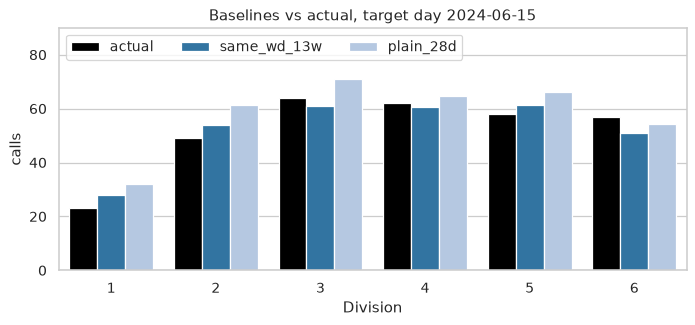

In [ ]:
long = compare.unpivot(index="DIVISION", variable_name="what", value_name="calls")
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.barplot(
    long.to_pandas(),
    x="DIVISION",
    y="calls",
    hue="what",
    ax=ax,
    palette=["black", "#1f77b4", "#aec7e8"],
)
ax.set(
    title=f"Baselines vs actual, target day {V2.target_start(issue)}", xlabel="Division"
)
ax.set_ylim(0, 90)
ax.legend(title=None, ncols=3, loc="upper left");